In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import os
# import joblib
# import warnings
# warnings.filterwarnings("ignore")


# from prophet import Prophet

# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_squared_error
# )

# pd.set_option("display.max_columns", None)

# print("Libraries loaded successfully.")


Libraries loaded successfully.


In [ ]:
# daily_sales = pd.read_csv(
#     "../data/processed/daily_sales_features.csv"
# )

# daily_sales["Date"] = pd.to_datetime(
#     daily_sales["Date"]
# )

# daily_sales = daily_sales.sort_values(
#     "Date"
# ).reset_index(drop=True)

# print("Shape:", daily_sales.shape)

# daily_sales.head()


Shape: (604, 19)


,Date,DailyRevenue,DailyQuantity,DailyOrders,DailyCustomers,DailyProducts,Year,Month,Quarter,DayOfWeek,WeekOfYear,IsWeekend,RevenueRolling7,RevenueRolling14,RevenueRolling30,RevenueLag1,RevenueLag7,RevenueLag14,RevenueLag30
0,2009-12-01,43894.87,24335,98,91,1042,2009,12,4,1,49,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-12-02,52762.06,29679,110,94,1087,2009,12,4,2,49,0,NaN,NaN,NaN,43894.87,NaN,NaN,NaN
2,2009-12-03,67413.62,48009,122,106,1082,2009,12,4,3,49,0,NaN,NaN,NaN,52762.06,NaN,NaN,NaN
3,2009-12-04,33913.81,19954,80,76,1006,2009,12,4,4,49,0,NaN,NaN,NaN,67413.62,NaN,NaN,NaN
4,2009-12-05,9803.05,5119,30,26,285,2009,12,4,5,49,1,NaN,NaN,NaN,33913.81,NaN,NaN,NaN


In [ ]:
# ## Inspect the date range

# print("Start date:")
# print(daily_sales["Date"].min())

# print("\nEnd date:")
# print(daily_sales["Date"].max())

# print("\nNumber of days:")
# print(daily_sales["Date"].nunique())

Start date:
2009-12-01 00:00:00

End date:
2011-12-09 00:00:00

Number of days:
604


In [ ]:
# ## Check missing dates
# ## This is important for time-series forecasting


# date_range = pd.date_range(
#     start=daily_sales["Date"].min(),
#     end=daily_sales["Date"].max(),
#     freq="D"
# )

# missing_dates = date_range.difference(
#     daily_sales["Date"]
# )

# print(
#     "Missing calendar dates:",
#     len(missing_dates)
# )

# print(missing_dates[:20])


Missing calendar dates: 135
DatetimeIndex(['2009-12-12', '2009-12-19', '2009-12-24', '2009-12-25',
               '2009-12-26', '2009-12-27', '2009-12-28', '2009-12-29',
               '2009-12-30', '2009-12-31', '2010-01-01', '2010-01-02',
               '2010-01-03', '2010-01-09', '2010-01-16', '2010-01-23',
               '2010-01-30', '2010-02-06', '2010-02-13', '2010-02-20'],
              dtype='datetime64[us]', freq=None)


In [ ]:
# ## Create a complete daily time series
# ## Daily Revenue

# daily_revenue = (
#     daily_sales[
#         ["Date", "DailyRevenue"]
#     ]
#     .copy()
# )

# daily_revenue = daily_revenue.set_index(
#     "Date"
# )

# daily_revenue = daily_revenue.asfreq(
#     "D"
# )

# daily_revenue["DailyRevenue"] = (
#     daily_revenue["DailyRevenue"]
#     .fillna(0)
# )

# daily_revenue = daily_revenue.reset_index()

# daily_revenue.head()



,Date,DailyRevenue
0,2009-12-01,43894.87
1,2009-12-02,52762.06
2,2009-12-03,67413.62
3,2009-12-04,33913.81
4,2009-12-05,9803.05


In [ ]:
# ## Verify the time series

# print(
#     "Rows:",
#     len(daily_revenue)
# )

# print(
#     "Missing revenue:",
#     daily_revenue["DailyRevenue"].isna().sum()
# )

# print(
#     "Start:",
#     daily_revenue["Date"].min()
# )

# print(
#     "End:",
#     daily_revenue["Date"].max()
# )

Rows: 739
Missing revenue: 0
Start: 2009-12-01 00:00:00
End: 2011-12-09 00:00:00


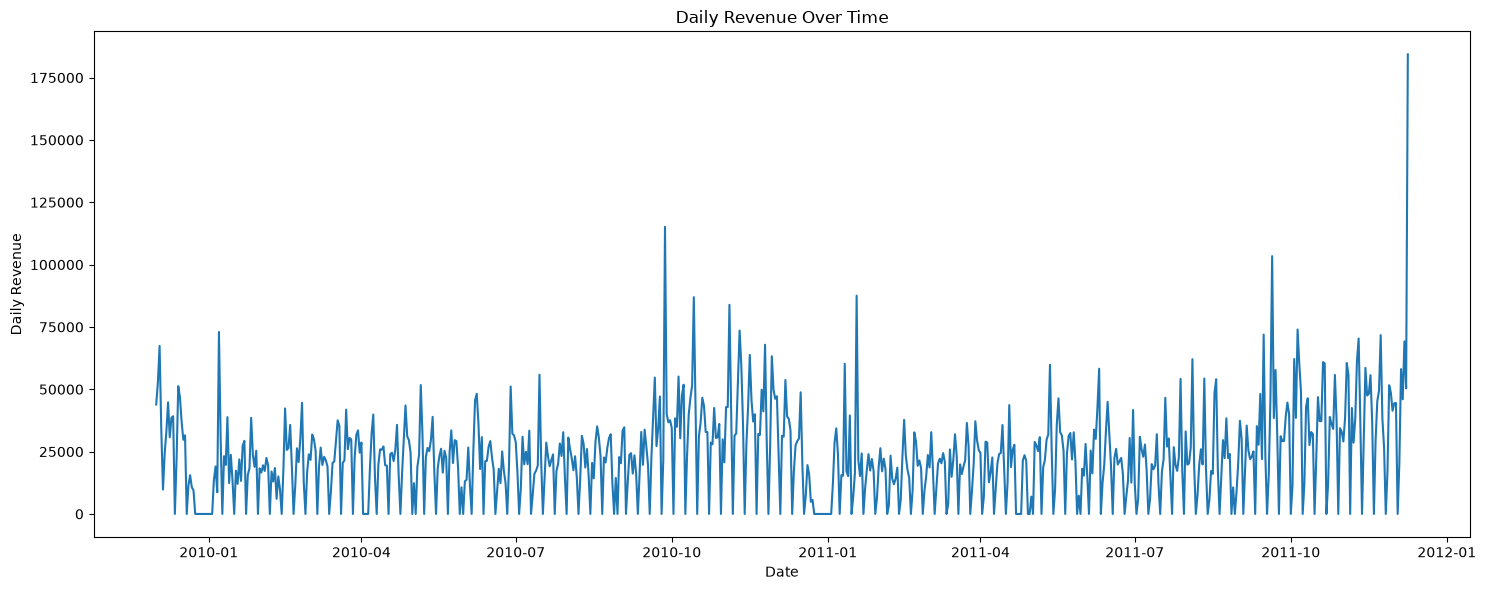

In [ ]:
# ## Visualize historical demand

# plt.figure(figsize=(15, 6))

# plt.plot(
#     daily_revenue["Date"],
#     daily_revenue["DailyRevenue"]
# )

# plt.title("Daily Revenue Over Time")
# plt.xlabel("Date")
# plt.ylabel("Daily Revenue")

# plt.tight_layout()
# plt.show()

In [ ]:
# ## Add a 7-day rolling average

# daily_revenue["Rolling7"] = (
#     daily_revenue["DailyRevenue"]
#     .rolling(7)
#     .mean()
# )

# daily_revenue.head(10)

,Date,DailyRevenue,Rolling7
0,2009-12-01,43894.87,NaN
1,2009-12-02,52762.06,NaN
2,2009-12-03,67413.62,NaN
3,2009-12-04,33913.81,NaN
4,2009-12-05,9803.05,NaN
5,2009-12-06,24390.10,NaN
6,2009-12-07,33002.49,37882.857143
7,2009-12-08,44763.34,38006.924286
8,2009-12-09,30763.17,34864.225714
9,2009-12-10,38598.21,30747.738571


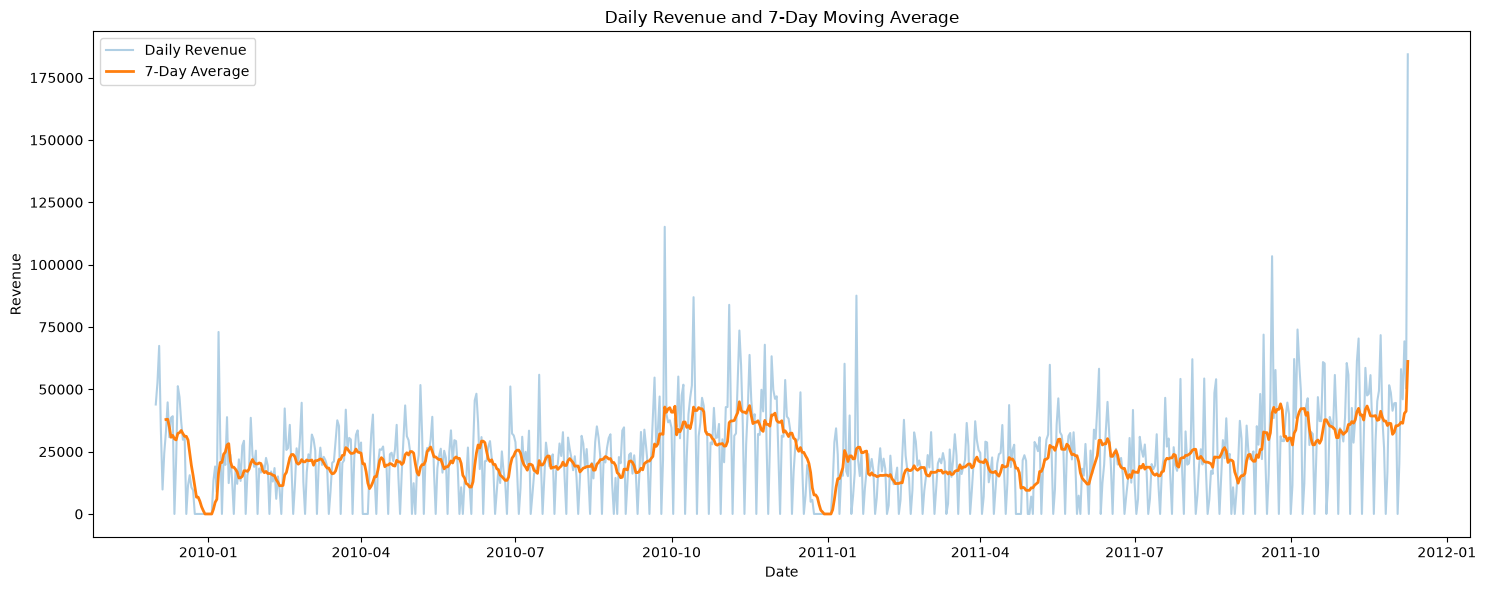

In [ ]:
# plt.figure(figsize=(15, 6))

# plt.plot(
#     daily_revenue["Date"],
#     daily_revenue["DailyRevenue"],
#     alpha=0.35,
#     label="Daily Revenue"
# )

# plt.plot(
#     daily_revenue["Date"],
#     daily_revenue["Rolling7"],
#     linewidth=2,
#     label="7-Day Average"
# )

# plt.title("Daily Revenue and 7-Day Moving Average")
# plt.xlabel("Date")
# plt.ylabel("Revenue")
# plt.legend()

# plt.tight_layout()
# plt.show()

In [ ]:
# ## Create the forecasting dataset

# forecast_data = daily_revenue[
#     ["Date", "DailyRevenue"]
# ].copy()

# forecast_data = forecast_data.rename(
#     columns={
#         "Date": "ds",
#         "DailyRevenue": "y"
#     }
# )

# forecast_data.head()


,ds,y
0,2009-12-01,43894.87
1,2009-12-02,52762.06
2,2009-12-03,67413.62
3,2009-12-04,33913.81
4,2009-12-05,9803.05


In [ ]:
# ## Check the forecasting data

# print(forecast_data.info())

# print(
#     "Missing dates:",
#     forecast_data["ds"].isna().sum()
# )

# print(
#     "Missing target:",
#     forecast_data["y"].isna().sum()
# )

<class 'pandas.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      739 non-null    datetime64[us]
 1   y       739 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 11.7 KB
None
Missing dates: 0
Missing target: 0


In [ ]:

# ## Create a time-based train/test split

# test_days = 90

# train = forecast_data.iloc[:-test_days].copy()

# test = forecast_data.iloc[-test_days:].copy()

# print("Training rows:", len(train))
# print("Testing rows:", len(test))

# print(
#     "\nTraining period:",
#     train["ds"].min(),
#     "→",
#     train["ds"].max()
# )

# print(
#     "Testing period:",
#     test["ds"].min(),
#     "→",
#     test["ds"].max()
# )

Training rows: 649
Testing rows: 90

Training period: 2009-12-01 00:00:00 → 2011-09-10 00:00:00
Testing period: 2011-09-11 00:00:00 → 2011-12-09 00:00:00


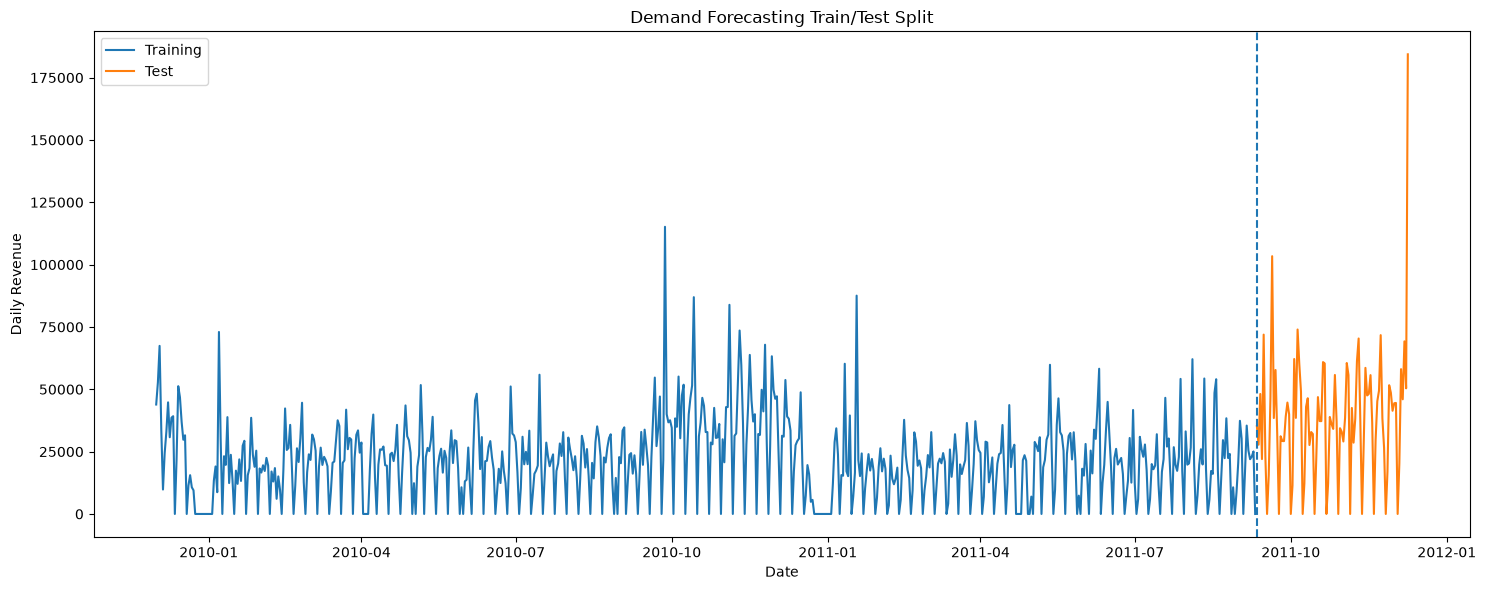

In [ ]:
# ## Visualize train/test split


# plt.figure(figsize=(15, 6))

# plt.plot(
#     train["ds"],
#     train["y"],
#     label="Training"
# )

# plt.plot(
#     test["ds"],
#     test["y"],
#     label="Test"
# )

# plt.axvline(
#     test["ds"].min(),
#     linestyle="--"
# )

# plt.title("Demand Forecasting Train/Test Split")
# plt.xlabel("Date")
# plt.ylabel("Daily Revenue")
# plt.legend()

# plt.tight_layout()
# plt.show()

In [ ]:
# # ## Build a naive baseline

# # ## Before using machine learning, we need a baseline.

# # A simple baseline will predict that tomorrow's revenue equals the previous day's revenue.

# test_baseline = test.copy()

# test_baseline["Predicted"] = (
#     forecast_data["y"]
#     .shift(1)
#     .iloc[-test_days:]
#     .values
# )

# test_baseline.head()


,ds,y,Predicted
649,2011-09-11,35206.92,0.00
650,2011-09-12,27777.36,35206.92
651,2011-09-13,48116.50,27777.36
652,2011-09-14,22013.75,48116.50
653,2011-09-15,71926.69,22013.75


In [ ]:
# ## Evaluate the baseline

# baseline_mae = mean_absolute_error(
#     test_baseline["y"],
#     test_baseline["Predicted"]
# )

# baseline_rmse = np.sqrt(
#     mean_squared_error(
#         test_baseline["y"],
#         test_baseline["Predicted"]
#     )
# )

# print("Baseline MAE:", round(baseline_mae, 2))
# print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 22699.28
Baseline RMSE: 30016.31


In [ ]:
# # Build the Prophet model

# # Now we'll train the actual forecasting model. 

# prophet_model = Prophet(
#     yearly_seasonality=True,
#     weekly_seasonality=True,
#     daily_seasonality=False,
#     seasonality_mode="multiplicative",
#     interval_width=0.95
# )

# prophet_model.fit(train)


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
11:46:51 - cmdstanpy - INFO - Chain [1] start processing
11:46:52 - cmdstanpy - INFO - Chain [1] done processing


In [ ]:
# # ## Generate test predictions

# # We need predictions only for the historical test period first.    

# test_dates = test[
#     ["ds"]
# ].copy()

# prophet_test_forecast = prophet_model.predict(
#     test_dates
# )

# prophet_test_forecast[
#     [
#         "ds",
#         "yhat",
#         "yhat_lower",
#         "yhat_upper"
#     ]
# ].head()



,ds,yhat,yhat_lower,yhat_upper
0,2011-09-11,14529.491011,-3578.062042,33938.236145
1,2011-09-12,23573.296827,4613.724893,42579.849678
2,2011-09-13,29655.697387,10539.165627,50084.571348
3,2011-09-14,27486.471072,9090.694498,46686.258017
4,2011-09-15,35351.665568,15047.975953,55533.433990


In [ ]:
# ## Compare actual vs predicted

# evaluation = test[
#     ["ds", "y"]
# ].merge(
#     prophet_test_forecast[
#         [
#             "ds",
#             "yhat",
#             "yhat_lower",
#             "yhat_upper"
#         ]
#     ],
#     on="ds",
#     how="left"
# )

# evaluation.head()


,ds,y,yhat,yhat_lower,yhat_upper
0,2011-09-11,35206.92,14529.491011,-3578.062042,33938.236145
1,2011-09-12,27777.36,23573.296827,4613.724893,42579.849678
2,2011-09-13,48116.50,29655.697387,10539.165627,50084.571348
3,2011-09-14,22013.75,27486.471072,9090.694498,46686.258017
4,2011-09-15,71926.69,35351.665568,15047.975953,55533.433990


In [ ]:
# # Calculate Prophet MAE

# prophet_mae = mean_absolute_error(
#     evaluation["y"],
#     evaluation["yhat"]
# )

# print(
#     "Prophet MAE:",
#     round(prophet_mae, 2)
# )

Prophet MAE: 12916.03


In [ ]:
# # Calculate Prophet RMSE

# prophet_rmse = np.sqrt(
#     mean_squared_error(
#         evaluation["y"],
#         evaluation["yhat"]
#     )
# )

# print(
#     "Prophet RMSE:",
#     round(prophet_rmse, 2)
# )

Prophet RMSE: 21806.61


In [ ]:
# # Calculate MAPE

# # MAPE can become problematic when actual values are zero, so we exclude zero-actual days.  

# non_zero = evaluation[
#     evaluation["y"] != 0
# ].copy()

# mape = (
#     np.abs(
#         (
#             non_zero["y"] -
#             non_zero["yhat"]
#         ) /
#         non_zero["y"]
#     ).mean()
#     * 100
# )

# print(
#     "Prophet MAPE:",
#     round(mape, 2),
#     "%"
# )


Prophet MAPE: 29.7 %


In [ ]:
# ## Create model comparison

# model_comparison = pd.DataFrame({
#     "Model": [
#         "Naive Baseline",
#         "Prophet"
#     ],
#     "MAE": [
#         baseline_mae,
#         prophet_mae
#     ],
#     "RMSE": [
#         baseline_rmse,
#         prophet_rmse
#     ],
#     "MAPE": [
#         np.nan,
#         mape
#     ]
# })

# model_comparison


,Model,MAE,RMSE,MAPE
0,Naive Baseline,22699.279356,30016.311341,NaN
1,Prophet,12916.034714,21806.609638,29.704937


In [ ]:
# # Determine which model is better

# if prophet_mae < baseline_mae:
#     print(
#         "Prophet performs better than the naive baseline based on MAE."
#     )
# else:
#     print(
#         "The naive baseline performs better than Prophet based on MAE."
#     )


Prophet performs better than the naive baseline based on MAE.


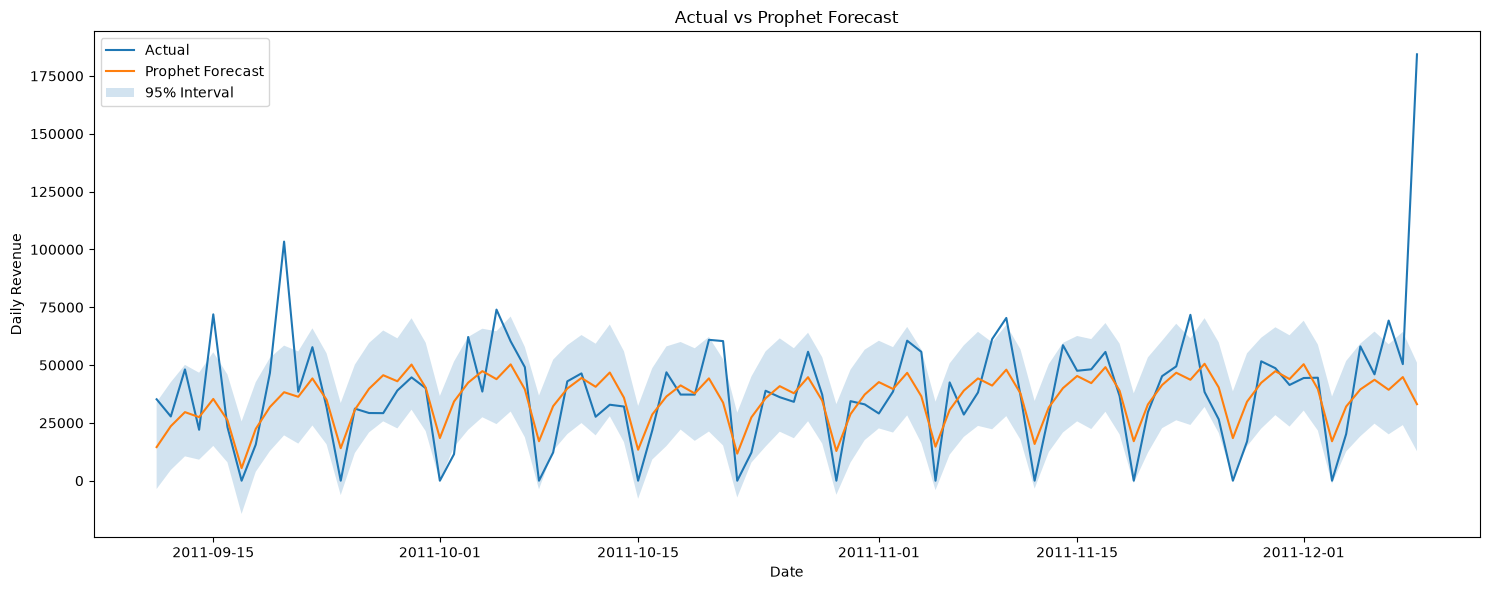

In [ ]:
# ## Visualize test predictions

# plt.figure(figsize=(15, 6))

# plt.plot(
#     evaluation["ds"],
#     evaluation["y"],
#     label="Actual"
# )

# plt.plot(
#     evaluation["ds"],
#     evaluation["yhat"],
#     label="Prophet Forecast"
# )

# plt.fill_between(
#     evaluation["ds"],
#     evaluation["yhat_lower"],
#     evaluation["yhat_upper"],
#     alpha=0.2,
#     label="95% Interval"
# )

# plt.title("Actual vs Prophet Forecast")
# plt.xlabel("Date")
# plt.ylabel("Daily Revenue")
# plt.legend()

# plt.tight_layout()
# plt.show()

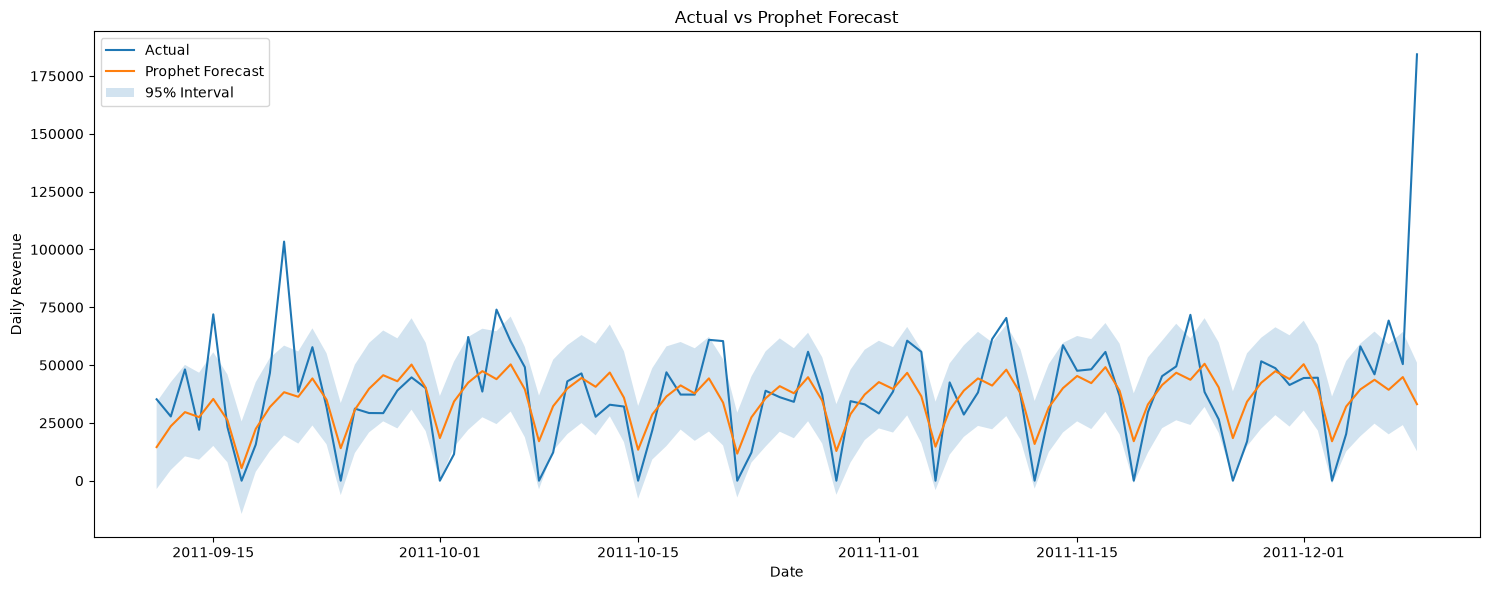

In [ ]:
# ## Save evaluation chart

# figure_dir = "../reports/figures"

# os.makedirs(
#     figure_dir,
#     exist_ok=True
# )

# plt.figure(figsize=(15, 6))

# plt.plot(
#     evaluation["ds"],
#     evaluation["y"],
#     label="Actual"
# )

# plt.plot(
#     evaluation["ds"],
#     evaluation["yhat"],
#     label="Prophet Forecast"
# )

# plt.fill_between(
#     evaluation["ds"],
#     evaluation["yhat_lower"],
#     evaluation["yhat_upper"],
#     alpha=0.2,
#     label="95% Interval"
# )

# plt.title("Actual vs Prophet Forecast")
# plt.xlabel("Date")
# plt.ylabel("Daily Revenue")
# plt.legend()

# plt.tight_layout()

# plt.savefig(
#     f"{figure_dir}/forecast_evaluation.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()

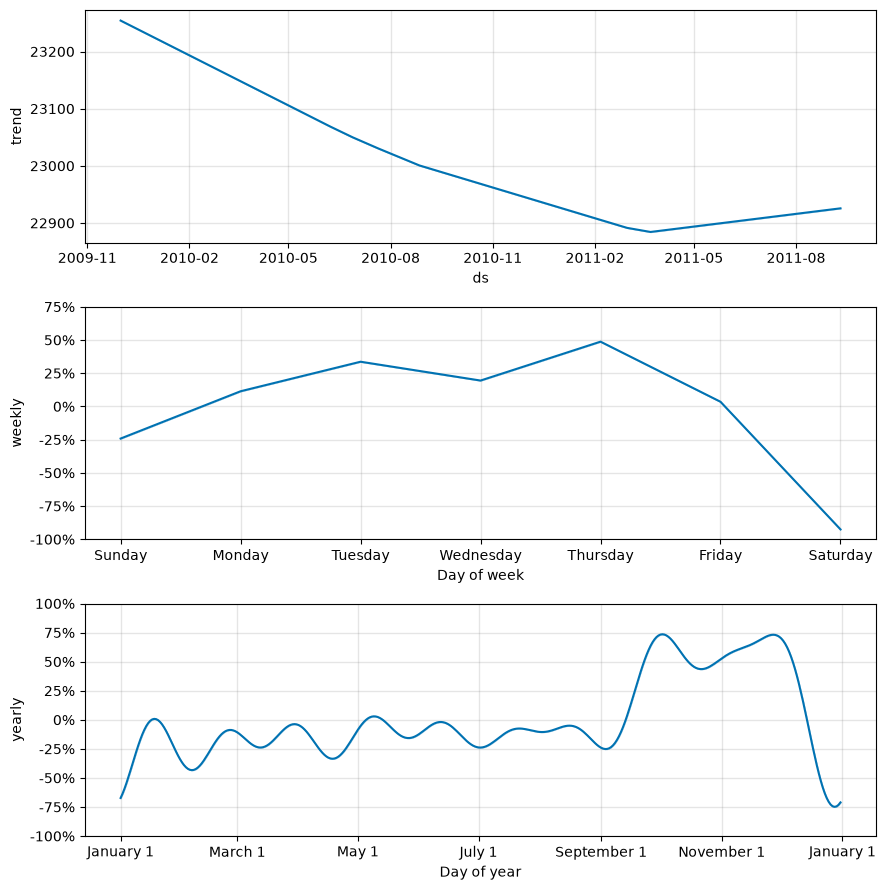

In [ ]:
# # Examine Prophet components

# # Prophet can separate the forecast into:

# # trend
# # weekly seasonality
# # yearly seasonality   


# fig = prophet_model.plot_components(
#     prophet_model.predict(train[["ds"]])
# )

# plt.show()


In [ ]:
# #  ## Train final forecasting model
# #  The previous Prophet model only saw the training period.

# # For our future 90-day forecast, we should now train the final model using all available historical data.


# final_model = Prophet(
#     yearly_seasonality=True,
#     weekly_seasonality=True,
#     daily_seasonality=False,
#     seasonality_mode="multiplicative",
#     interval_width=0.95
# )

# final_model.fit(
#     forecast_data
# )

11:53:27 - cmdstanpy - INFO - Chain [1] start processing
11:53:28 - cmdstanpy - INFO - Chain [1] done processing


In [ ]:
# # ## Create a 90-day future dataframe
# # Our project configuration already specifies:

# # forecast horizon = 90 days

# forecast_horizon = 90

# future = final_model.make_future_dataframe(
#     periods=forecast_horizon,
#     freq="D"
# )

# print(
#     "Future dataframe shape:",
#     future.shape
# )

# future.tail()

Future dataframe shape: (829, 1)


,ds
824,2012-03-04
825,2012-03-05
826,2012-03-06
827,2012-03-07
828,2012-03-08


In [ ]:
# ## Generate the future forecast

# future_forecast = final_model.predict(
#     future
# )

# future_forecast[
#     [
#         "ds",
#         "yhat",
#         "yhat_lower",
#         "yhat_upper"
#     ]
# ].tail(90)


,ds,yhat,yhat_lower,yhat_upper
739,2011-12-10,13921.366811,-10139.225598,36916.660924
740,2011-12-11,32532.255638,10405.059652,53693.738383
741,2011-12-12,42451.864953,20326.874870,65421.171090
742,2011-12-13,46019.777926,21995.422019,67838.213488
743,2011-12-14,40650.560746,18162.635571,62862.667958
...,...,...,...,...
824,2012-03-04,18251.139231,-4673.385759,40449.469569
825,2012-03-05,30391.145804,6538.609625,54058.223549
826,2012-03-06,35873.254792,13673.631044,56053.028328
827,2012-03-07,31902.426498,9936.594023,54366.824090


In [ ]:
# ## Keep only the future dates  

# future_only = future_forecast[
#     future_forecast["ds"] >
#     forecast_data["ds"].max()
# ].copy()

# print(
#     "Future forecast rows:",
#     len(future_only)
# )

Future forecast rows: 90


In [ ]:
# # ## Prevent negative forecasts

# # Revenue cannot be negative.

# # Prophet's mathematical forecast can theoretically produce a negative lower bound or prediction.

# # We'll ensure the business-facing forecast isn't negative.  


# future_only["yhat"] = (
#     future_only["yhat"].clip(lower=0)
# )

# future_only["yhat_lower"] = (
#     future_only["yhat_lower"].clip(lower=0)
# )

# future_only["yhat_upper"] = (
#     future_only["yhat_upper"].clip(lower=0)
# )


In [ ]:
# ## Rename forecast columns  

# future_forecast_output = future_only[
#     [
#         "ds",
#         "yhat",
#         "yhat_lower",
#         "yhat_upper"
#     ]
# ].rename(
#     columns={
#         "ds": "Date",
#         "yhat": "ForecastRevenue",
#         "yhat_lower": "LowerBound",
#         "yhat_upper": "UpperBound"
#     }
# )

# future_forecast_output.head()


,Date,ForecastRevenue,LowerBound,UpperBound
739,2011-12-10,13921.366811,0.000000,36916.660924
740,2011-12-11,32532.255638,10405.059652,53693.738383
741,2011-12-12,42451.864953,20326.874870,65421.171090
742,2011-12-13,46019.777926,21995.422019,67838.213488
743,2011-12-14,40650.560746,18162.635571,62862.667958


In [ ]:
# ## Add forecast calendar features 

# future_forecast_output["Year"] = (
#     future_forecast_output["Date"].dt.year
# )

# future_forecast_output["Month"] = (
#     future_forecast_output["Date"].dt.month
# )

# future_forecast_output["MonthName"] = (
#     future_forecast_output["Date"].dt.month_name()
# )

# future_forecast_output["DayOfWeek"] = (
#     future_forecast_output["Date"].dt.dayofweek
# )

# future_forecast_output["DayName"] = (
#     future_forecast_output["Date"].dt.day_name()
# )

# future_forecast_output["IsWeekend"] = (
#     future_forecast_output["DayOfWeek"] >= 5
# ).astype(int)

# future_forecast_output.head()


,Date,ForecastRevenue,LowerBound,UpperBound,Year,Month,MonthName,DayOfWeek,DayName,IsWeekend
739,2011-12-10,13921.366811,0.000000,36916.660924,2011,12,December,5,Saturday,1
740,2011-12-11,32532.255638,10405.059652,53693.738383,2011,12,December,6,Sunday,1
741,2011-12-12,42451.864953,20326.874870,65421.171090,2011,12,December,0,Monday,0
742,2011-12-13,46019.777926,21995.422019,67838.213488,2011,12,December,1,Tuesday,0
743,2011-12-14,40650.560746,18162.635571,62862.667958,2011,12,December,2,Wednesday,0


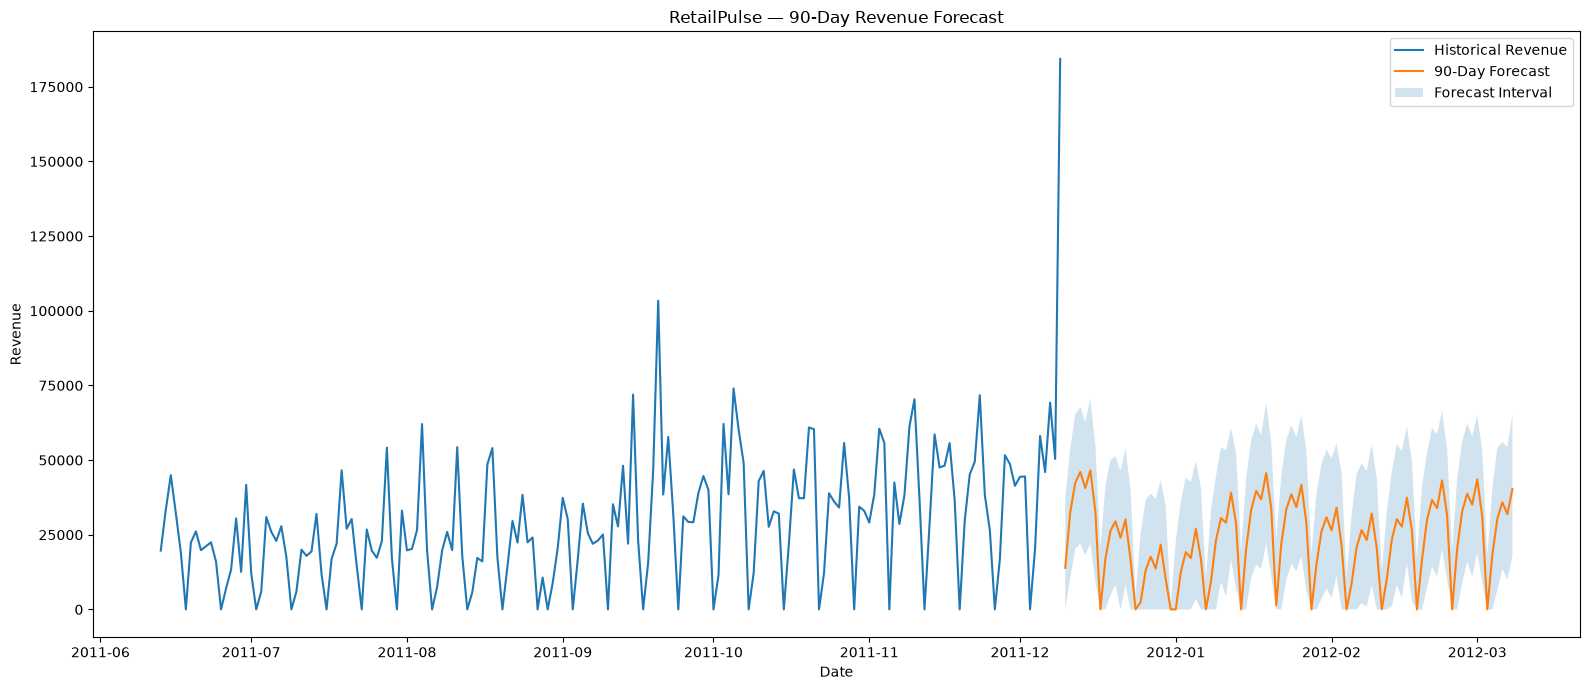

In [ ]:
# ## Visualize the 90-day forecast 

# plt.figure(figsize=(16, 7))

# historical_plot = forecast_data.tail(180)

# plt.plot(
#     historical_plot["ds"],
#     historical_plot["y"],
#     label="Historical Revenue"
# )

# plt.plot(
#     future_forecast_output["Date"],
#     future_forecast_output["ForecastRevenue"],
#     label="90-Day Forecast"
# )

# plt.fill_between(
#     future_forecast_output["Date"],
#     future_forecast_output["LowerBound"],
#     future_forecast_output["UpperBound"],
#     alpha=0.2,
#     label="Forecast Interval"
# )

# plt.title(
#     "RetailPulse — 90-Day Revenue Forecast"
# )

# plt.xlabel("Date")
# plt.ylabel("Revenue")

# plt.legend()

# plt.tight_layout()
# plt.show()

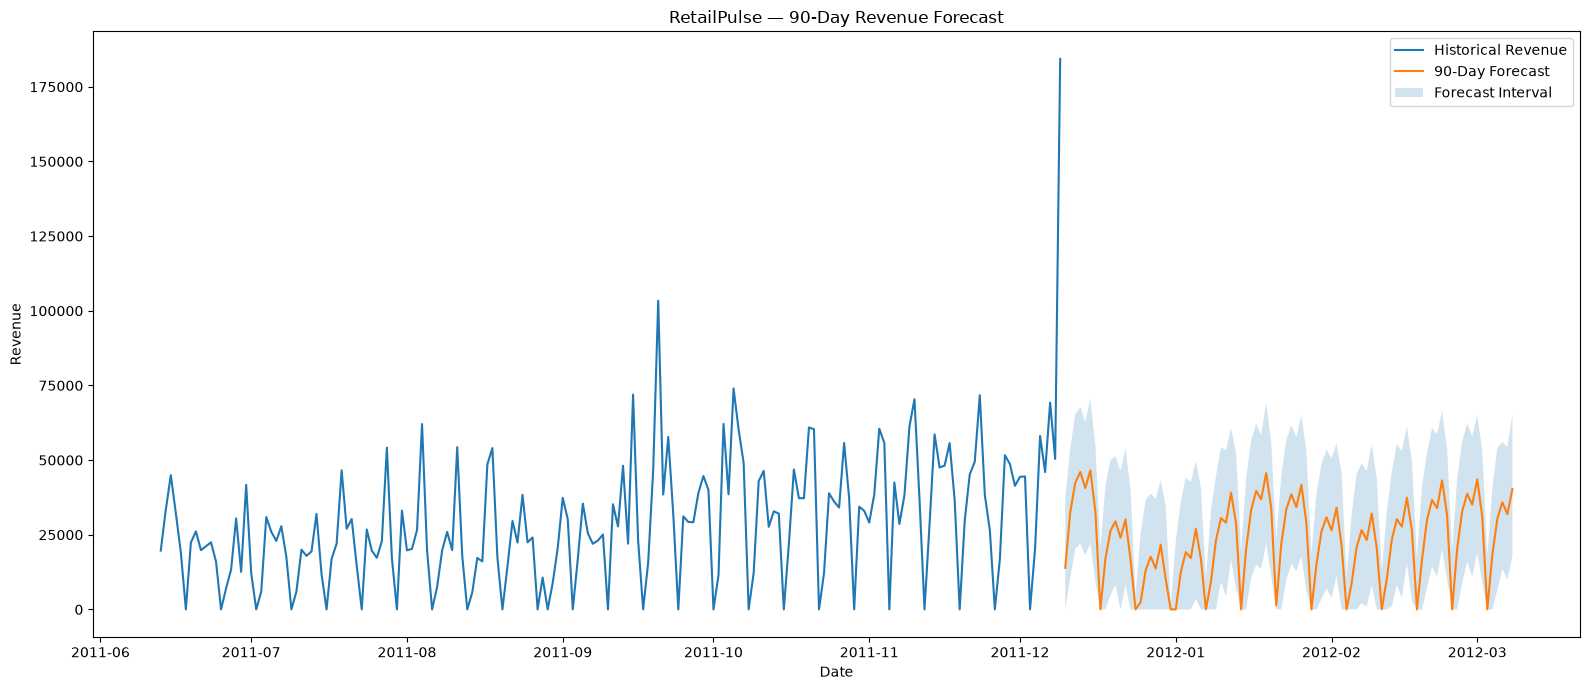

In [ ]:
# ## Save forecast chart  

# plt.figure(figsize=(16, 7))

# plt.plot(
#     historical_plot["ds"],
#     historical_plot["y"],
#     label="Historical Revenue"
# )

# plt.plot(
#     future_forecast_output["Date"],
#     future_forecast_output["ForecastRevenue"],
#     label="90-Day Forecast"
# )

# plt.fill_between(
#     future_forecast_output["Date"],
#     future_forecast_output["LowerBound"],
#     future_forecast_output["UpperBound"],
#     alpha=0.2,
#     label="Forecast Interval"
# )

# plt.title(
#     "RetailPulse — 90-Day Revenue Forecast"
# )

# plt.xlabel("Date")
# plt.ylabel("Revenue")

# plt.legend()

# plt.tight_layout()

# plt.savefig(
#     f"{figure_dir}/90_day_revenue_forecast.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# plt.show()


In [ ]:
# # Calculate total expected revenue

# expected_90_day_revenue = (
#     future_forecast_output["ForecastRevenue"]
#     .sum()
# )

# print(
#     "Expected revenue for next 90 days:",
#     f"{expected_90_day_revenue:,.2f}"
# )

Expected revenue for next 90 days: 2,130,963.00


In [ ]:
# ## Calculate average daily forecast

# average_daily_forecast = (
#     future_forecast_output["ForecastRevenue"]
#     .mean()
# )

# print(
#     "Average forecasted daily revenue:",
#     f"{average_daily_forecast:,.2f}"
# )

Average forecasted daily revenue: 23,677.37


In [ ]:
# ## Find highest forecasted days   

# top_forecast_days = (
#     future_forecast_output
#     .sort_values(
#         "ForecastRevenue",
#         ascending=False
#     )
#     .head(10)
# )

# top_forecast_days[
#     [
#         "Date",
#         "ForecastRevenue",
#         "LowerBound",
#         "UpperBound"
#     ]
# ]

,Date,ForecastRevenue,LowerBound,UpperBound
744,2011-12-15,46577.742611,22037.966451,70427.369473
742,2011-12-13,46019.777926,21995.422019,67838.213488
779,2012-01-19,45628.835984,22155.193915,69199.078725
821,2012-03-01,43576.266212,18751.570851,65034.943807
814,2012-02-23,43204.272653,20272.922835,66428.368992
741,2011-12-12,42451.864953,20326.874870,65421.171090
786,2012-01-26,41758.295474,17875.464659,64989.969969
743,2011-12-14,40650.560746,18162.635571,62862.667958
828,2012-03-08,40304.772208,17806.195173,65324.203972
777,2012-01-17,39706.108193,14977.281493,62166.267056


In [39]:
# ## Create monthly forecast summary

# This will be very useful for Power BI.  


future_forecast_output["YearMonth"] = (
    future_forecast_output["Date"]
    .dt.to_period("M")
    .astype(str)
)

monthly_forecast = (
    future_forecast_output
    .groupby("YearMonth")
    .agg(
        ForecastRevenue=("ForecastRevenue", "sum"),
        LowerBound=("LowerBound", "sum"),
        UpperBound=("UpperBound", "sum")
    )
    .reset_index()
)

monthly_forecast

,YearMonth,ForecastRevenue,LowerBound,UpperBound
0,2011-12,477102.965355,123315.692553,9.381849e+05
1,2012-01,734490.974502,185501.557539,1.432734e+06
2,2012-02,688073.149470,155818.075807,1.335939e+06
3,2012-03,231295.909678,75739.644953,4.067743e+05


In [40]:
## Save the daily forecast  

processed_dir = "../data/processed"

os.makedirs(
    processed_dir,
    exist_ok=True
)

future_forecast_output.to_csv(
    f"{processed_dir}/revenue_forecast_90_days.csv",
    index=False
)

print(
    "Saved:",
    f"{processed_dir}/revenue_forecast_90_days.csv"
)

Saved: ../data/processed/revenue_forecast_90_days.csv


In [41]:
## Save monthly forecast  

monthly_forecast.to_csv(
    f"{processed_dir}/monthly_revenue_forecast.csv",
    index=False
)

print(
    "Saved:",
    f"{processed_dir}/monthly_revenue_forecast.csv"
)

Saved: ../data/processed/monthly_revenue_forecast.csv


In [42]:
## Save model evaluation   

evaluation_results = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Prophet"
    ],
    "MAE": [
        baseline_mae,
        prophet_mae
    ],
    "RMSE": [
        baseline_rmse,
        prophet_rmse
    ],
    "MAPE": [
        np.nan,
        mape
    ]
})

evaluation_results.to_csv(
    f"{processed_dir}/forecast_model_evaluation.csv",
    index=False
)

evaluation_results


,Model,MAE,RMSE,MAPE
0,Naive Baseline,22699.279356,30016.311341,NaN
1,Prophet,12916.034714,21806.609638,29.704937


In [43]:
# ## Save the final Prophet model

# Prophet models can be serialized with joblib for this project.    

model_dir = "../models"

os.makedirs(
    model_dir,
    exist_ok=True
)

joblib.dump(
    final_model,
    f"{model_dir}/revenue_forecast_prophet.pkl"
)

print(
    "Prophet model saved."
)


Prophet model saved.


In [44]:
## Save forecasting metadata   


forecast_metadata = {
    "target": "DailyRevenue",
    "model": "Prophet",
    "forecast_horizon_days": 90,
    "train_start": str(train["ds"].min()),
    "train_end": str(train["ds"].max()),
    "test_start": str(test["ds"].min()),
    "test_end": str(test["ds"].max()),
    "baseline_mae": float(baseline_mae),
    "baseline_rmse": float(baseline_rmse),
    "prophet_mae": float(prophet_mae),
    "prophet_rmse": float(prophet_rmse),
    "prophet_mape": float(mape),
    "expected_90_day_revenue": float(
        expected_90_day_revenue
    )
}

import json

with open(
    "../reports/outputs/forecast_metadata.json",
    "w"
) as f:
    json.dump(
        forecast_metadata,
        f,
        indent=4
    )

print("Forecast metadata saved.")


Forecast metadata saved.


In [ ]:
## Final validation 

print("=" * 70)
print("RETAILPULSE DEMAND FORECASTING COMPLETE")
print("=" * 70)

print(
    f"Historical days: "
    f"{len(forecast_data):,}"
)

print(
    f"Training days: "
    f"{len(train):,}"
)

print(
    f"Test days: "
    f"{len(test):,}"
)

print(
    f"Baseline MAE: "
    f"{baseline_mae:,.2f}"
)

print(
    f"Prophet MAE: "
    f"{prophet_mae:,.2f}"
)

print(
    f"Prophet RMSE: "
    f"{prophet_rmse:,.2f}"
)

print(
    f"Prophet MAPE: "
    f"{mape:.2f}%"
)

print(
    f"Future forecast horizon: "
    f"{len(future_forecast_output)} days"
)

print(
    f"Expected 90-day revenue: "
    f"{expected_90_day_revenue:,.2f}"
)

print("=" * 70)



RETAILPULSE DEMAND FORECASTING COMPLETE
Historical days: 739
Training days: 649
Test days: 90
Baseline MAE: 22,699.28
Prophet MAE: 12,916.03
Prophet RMSE: 21,806.61
Prophet MAPE: 29.70%
Future forecast horizon: 90 days
Expected 90-day revenue: 2,130,963.00


: 